# Data Mining project: `health` dataset

* Group: Group 10

Organisation. This notebook is the short report: it presents each discovery with the method that shows it. The details are in the appendices:
* [`01_cleaning_health.ipynb`](01_cleaning_health.ipynb): all the cleaning, step by step;
* [`02_analysis_health.ipynb`](02_analysis_health.ipynb): the full analysis, course by course, including the methods that brought nothing;
* [`health_utils.py`](health_utils.py): the loading functions and the long computations. The method choices (algorithms, parameters, thresholds) remain visible here.

*Use of generative AI: this work was done with the help of Claude (Anthropic). The assistant wrote most of the code and texts, and proposed methods and interpretation leads. On our side, we chose the steps, discussed and validated every cleaning and analysis decision, reviewed the results, and asked for corrections when a figure or an interpretation did not hold.*

## Summary

The `health` dataset contains two phenomena, which never affect the same patients.

1. A rejuvenation programme reserved for executives. 8 executives have received repeated `MRP-42` injections since 2014, all performed by the same doctor. Each of the first 3 doses lowers their biological age by about 3.5 years. The lots are reserved in the order of the hierarchy, and lot no. 1 is missing. The "research" on ordinary patients comes afterwards and has no effect. 9 other patients rejuvenate in the same way, with no recorded injection. Finally, the encounters of 20 June 2025 were probably invented.
2. Ten patients with highly unusual physical measurements. They have two independent cardiac rhythms, eyes that move separately and an unstable identity on camera. Their official notes downplay everything. One of them is linked to a public figure, "Elias Voss".

By crossing with the other datasets (section 7), the two phenomena meet: each injection of the executives matches a stock withdrawal on the same day, and the product reaches the clinic through Meridian BioLogistics, the company chaired by Elias Voss.

## 0. Data and cleaning

All 7 files of the dataset are used. The cleaning (appendix 01) fixes duplicates, inconsistent spellings, badly formatted dates and numbers, and removes constant columns. The extreme values are flagged but kept, because they are precisely what we are looking for.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import health_utils as hu

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)

tables = hu.load()
P, E, PR, CR, SIG, N = tables["P"], tables["E"], tables["PR"], tables["CR"], tables["SIG"], tables["N"]
MEDICAL = tables["MEDICAL"]
occ = P.set_index("patient_number")["occupation_text"]
W2, feat = hu.patient_features(tables)

display(tables["sizes"])
display(hu.cleaning_summary(tables["LOG"]))
print("variables built per patient:", feat.shape)

,rows,columns
patient_administration,240,12
clinical_encounters,1067,12
clinical_observations,17734,12
clinical_procedures,310,12
cardiac_recordings,44,15
cardiac_signal_samples,96925,4
clinical_notes,30,10


,rows_affected,files
operation,,
exact duplicate removed,6,"patient_administration, clinical_encounters, c..."
extra spaces,57,"patient_administration, clinical_encounters, c..."
capitalisation,96,"patient_administration, clinical_encounters, c..."
majority spelling,1,patient_administration
null/NA/N/A -> missing,59,"clinical_encounters, clinical_observations, cl..."
date put back in standard format,15,"patient_administration, clinical_encounters, c..."
comma replaced by a point,180,clinical_observations
attached unit removed,160,clinical_observations
constant column removed,18206,"clinical_observations, clinical_procedures, ca..."


variables built per patient: (240, 89)


## 1. Two groups of patients stand out on their own

Question: are there patients who do not look like the others, without telling the algorithms whom to look for?

Method. We built nearly 90 variables per patient from all the files: median, variability and evolution of each measurement, anomaly counts, encounters, procedures, ECGs and notes.
* Course 1: Pearson and Spearman correlations on all the pairs (about 3,700).
* Course 2: clustering on the 27 standardised medical measurements (PCA, hierarchical clustering, DBSCAN). The procedures and the occupation are not used to form the groups, only to interpret them.

In [2]:
sweep = hu.correlation_sweep(feat.drop(columns="N_MRP42"))
display(sweep.sort_values("spearman", key=abs, ascending=False).head(8).round(2))

,variable 1,variable 2,pearson,spearman,gap
181,BIOAGE,AGE,0.95,0.95,-0.00
3304,BINOCOORD_ATYP,VISIT_ocular_assessment,0.67,0.81,-0.14
3632,VISIT_research_procedure,PROC_MRP-42,0.33,0.80,-0.47
3359,N_DISCORDANT,VISIT_cardiac_assessment,0.69,0.75,-0.07
8,APICAL,PPULSE,0.76,0.75,0.00
3332,VESTIB_ABNORMAL,VISIT_mobility_assessment,0.89,0.72,0.17
618,MOBILITY,WALKSPD,0.73,0.71,0.02
1431,BIOAGE_STD,N_VISITS,0.68,0.69,-0.01


Apart from the expected links (biological age and actual age, heart and wrist pulse), two signals stand out:
* anomalies go with targeted examinations: atypical eye coordination and ocular assessments, discordant pulses and cardiac assessments;
* the "research" encounters go with the `MRP-42` procedure, and sudden drops in biological age with "executive health reviews" (details in appendix 02, section 1.6).

In [3]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import AgglomerativeClustering, DBSCAN, KMeans
from sklearn.metrics import silhouette_score
from sklearn.neighbors import NearestNeighbors

Z = StandardScaler().fit_transform(feat[MEDICAL].fillna(feat[MEDICAL].median()))
pca = PCA().fit(Z)
print("PCA - variables carrying axis 1:", list(pd.Series(abs(pca.components_[0]), MEDICAL).nlargest(5).index))

hierarchical = AgglomerativeClustering(2, linkage="average").fit_predict(Z)
dist5 = np.sort(NearestNeighbors(n_neighbors=5).fit(Z).kneighbors(Z)[0][:, -1])
outside_group = DBSCAN(eps=np.quantile(dist5, .9), min_samples=5).fit_predict(Z) == -1
print(f"hierarchical average k=2: silhouette {silhouette_score(Z, hierarchical):.2f}, small group of {np.bincount(hierarchical).min()} patients")
print("DBSCAN (eps = 90th percentile of the distances to the 5th neighbour):", outside_group.sum(), "patients outside any group")

small = (hierarchical != np.bincount(hierarchical).argmax()) & outside_group
display(feat.loc[small, ["PULSE_GAP", "THORPEAK", "LATSWAY", "IDCONS", "CAMMATCH", "N_DISCORDANT", "N_OCULAR_ATYP"]]
        .round(1).join(occ))

PCA - variables carrying axis 1: ['PULSE_GAP', 'IDCONS', 'THORPEAK', 'THORVIB', 'CAMMATCH']
hierarchical average k=2: silhouette 0.24, small group of 13 patients
DBSCAN (eps = 90th percentile of the distances to the 5th neighbour): 15 patients outside any group


,PULSE_GAP,THORPEAK,LATSWAY,IDCONS,CAMMATCH,N_DISCORDANT,N_OCULAR_ATYP,occupation_text
patient_number,,,,,,,,
PAT-31012,16.2,53.6,46.3,85.3,55.0,3.0,3.0,research professional
PAT-31037,27.0,44.6,74.2,66.7,68.0,5.0,4.0,research professional
PAT-31040,19.9,59.9,77.2,71.1,80.8,5.0,0.0,research professional
PAT-31065,29.8,55.5,58.0,91.3,74.1,6.0,5.0,clinical specialist
PAT-31086,27.2,80.7,54.8,76.2,59.2,6.0,0.0,corporate adviser
PAT-31115,14.5,51.2,70.2,71.7,72.2,3.0,2.0,clinical specialist
PAT-31162,15.7,68.2,60.0,68.6,73.7,3.0,4.0,corporate adviser
PAT-31186,24.1,65.9,50.3,96.7,81.9,5.0,4.0,corporate adviser
PAT-31215,26.3,55.1,67.6,78.2,82.6,6.0,0.0,research professional


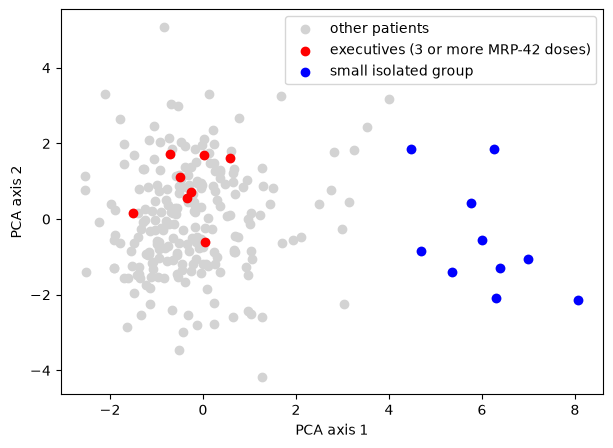

In [4]:
coords = pca.transform(Z)
executives = (feat["N_MRP42"] >= 3).values
plt.figure(figsize=(7, 5))
plt.scatter(coords[:, 0], coords[:, 1], color="lightgrey", label="other patients")
plt.scatter(coords[executives, 0], coords[executives, 1], color="red", label="executives (3 or more MRP-42 doses)")
plt.scatter(coords[small, 0], coords[small, 1], color="blue", label="small isolated group")
plt.xlabel("PCA axis 1")
plt.ylabel("PCA axis 2")
plt.legend()
plt.show()

On the chart, the small group (in blue) is clearly apart from the cloud, whereas the executives (in red) are mixed with the other patients. PCA axis 1 gathers exactly the anomalies of course 1. Hierarchical clustering and DBSCAN isolate the same 10 patients. They have a large pulse gap, a high thoracic peak and sway, often low identity or camera, and many "discordant" pulses, although these counts were not used for the clustering. They all have a discreet occupation: `research professional`, `corporate adviser` or `clinical specialist`. The silhouettes remain low, because the rest of the patients forms a single cloud. The comparison of all the methods (k-means, 3 linkages, 6 DBSCAN settings, t-SNE) is in appendix 02, section 2.3.

The executives are only distinguished by their age. We therefore redo a clustering on the ageing variables alone.

In [5]:
AGE_VARS = ["AGE_GAP", "BIOAGE_SLOPE", "MAX_AGE_DROP"]
Z_age = StandardScaler().fit_transform(feat[AGE_VARS].fillna(feat[AGE_VARS].median()))
km = KMeans(2, n_init=20, random_state=0).fit_predict(Z_age)
print(f"k-means k=2 on ageing: silhouette {silhouette_score(Z_age, km):.2f}")
rejuvenated = feat.index[km == np.bincount(km).argmin()]

grp = pd.Series("other", index=feat.index)
grp[small] = "PHENO"
grp[rejuvenated] = "UNDECLARED_REJUVENATED"
grp[feat["N_MRP42"] >= 3] = "ELITE"
E["group"] = E["patient_number"].map(grp)
display(feat.groupby(grp)[["AGE_GAP", "BIOAGE_SLOPE", "N_MRP42"]].median().round(1).assign(patients=grp.value_counts()))

k-means k=2 on ageing: silhouette 0.79


,AGE_GAP,BIOAGE_SLOPE,N_MRP42,patients
ELITE,-11.7,-0.9,4.0,8
PHENO,-4.1,1.0,0.0,10
UNDECLARED_REJUVENATED,-8.5,-0.5,0.0,9
other,-0.7,1.0,0.0,213


The separation is very clear (silhouette 0.79). The small group has 17 rejuvenated patients: the 8 executives who received at least 3 doses of `MRP-42`, and 9 patients with no recorded repeated treatment. We obtain three groups, used throughout the rest:
* ELITE: the 8 executives treated with `MRP-42`;
* UNDECLARED_REJUVENATED: the 9 rejuvenated patients with no recorded treatment;
* PHENO: the 10 patients with an atypical physical profile.

## 2. The elite's `MRP-42` programme

Question: who receives `MRP-42`, who administers it, at what rhythm, and with what effect?

Methods: co-occurrences (course 3), Louvain communities and process mining (course 4), before/after effect of each dose and timeline (course 5).

In [6]:
mrp = PR[PR["procedure_code"] == "MRP-42"].copy()
mrp["group"] = mrp["patient_number"].map(grp)
display(pd.crosstab([mrp["performing_license_number"], mrp["authorization_class"]], mrp["group"]))
display(feat.loc[grp == "ELITE", ["N_MRP42", "AGE", "AGE_GAP", "BIOAGE_SLOPE"]].round(1).join(occ).sort_values("AGE_GAP"))

group                                            ELITE  UNDECLARED_REJUVENATED  other
performing_license_number authorization_class                                        
LIC-VLN-MED-1001          research_restricted        0                       0      1
LIC-VLN-MED-1002          research_restricted        0                       1      5
                          restricted_specialist     30                       0      0
LIC-VLN-MED-1003          research_restricted        0                       0      1
LIC-VLN-MED-1004          research_restricted        0                       0      3
LIC-VLN-MED-1006          research_restricted        0                       0      4
LIC-VLN-RES-1016          research_restricted        0                       0      3
LIC-VLN-RES-1044          research_restricted        0                       0      2

,N_MRP42,AGE,AGE_GAP,BIOAGE_SLOPE,occupation_text
patient_number,,,,,
PAT-31119,4.0,69.8,-14.1,-0.9,Chief executive of Solvane Energy Group
PAT-31044,4.0,66.5,-12.5,0.3,Senior minister of the Avelora Federation
PAT-31074,4.0,73.6,-12.4,-0.9,Executive chair of Nivren Maritime Logistics
PAT-31183,3.0,60.3,-12.0,-0.9,Executive director of Ardena Capital Union
PAT-31174,4.0,75.7,-11.4,-0.2,Regional governor in the Tembara Commonwealth
PAT-31142,3.0,69.0,-10.9,-0.9,Chair of Belen Agro-Industries
PAT-31221,5.0,72.9,-10.6,0.2,Head of government of Kintara Republic
PAT-31099,3.0,80.9,-8.9,-1.0,Retired political intermediary and former coun...


* The 30 doses of the executives ("specialist restricted" class) are all performed by `LIC-VLN-MED-1002`. They are a head of government, a minister, a governor, CEOs and a former political intermediary.
* Their biological age is 9 to 14 years lower than their actual age. For 6 of them, it decreases over time (median slope of −0.9 year per year), whereas it increases by 1 year per year in the other patients.
* 20 patients received a single dose, classified "research restricted". One of them is an undeclared rejuvenated patient.

Could this be chance? We draw 8 patients at random among the 240 10,000 times, and compute each time their mean gap between biological and actual age. If no draw is as low as the executives, chance is ruled out.

executives: -11.6 years
8 random patients: -1.3 years on average, -7.3 at the lowest
share of the draws as low as the executives: 0.0


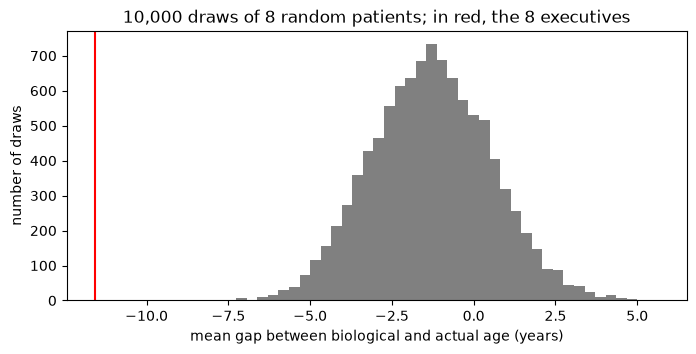

In [7]:
rng = np.random.default_rng(0)
observed = feat.loc[grp == "ELITE", "AGE_GAP"].mean()
chance = []
for i in range(10000):
    draw = rng.choice(feat["AGE_GAP"].values, size=8, replace=False)
    chance.append(draw.mean())
chance = np.array(chance)

print(f"executives: {observed:.1f} years")
print(f"8 random patients: {chance.mean():.1f} years on average, {chance.min():.1f} at the lowest")
print("share of the draws as low as the executives:", (chance <= observed).mean())

plt.figure(figsize=(8, 3.5))
plt.hist(chance, bins=40, color="grey")
plt.axvline(observed, color="red")
plt.xlabel("mean gap between biological and actual age (years)")
plt.ylabel("number of draws")
plt.title("10,000 draws of 8 random patients; in red, the 8 executives")
plt.show()

None of the 10,000 draws is as low as the executives: chance is ruled out. This test shows that the executives differ from the other patients, not that `MRP-42` is what rejuvenates them. It is the effect measured dose by dose, further down, that points in this direction.

We check that this doctor also structures the network. We connect two patients if they are followed by the same doctors, then look for communities with Louvain, varying the threshold and the initialisation.

In [8]:
import networkx as nx
from networkx.algorithms import community as nxc

profile, similarity = hu.doctor_similarity(E)
elite_ids = set(grp[grp == "ELITE"].index)
stability = []
for q in [.9, .95, .98]:
    G = hu.patient_graph(profile, similarity, q)
    for seed in [0, 1, 2]:
        comms = nxc.louvain_communities(G, weight="weight", seed=seed)
        c = max(comms, key=lambda c: len(c & elite_ids))
        stability.append({"threshold": q, "seed": seed, "modularity": round(nxc.modularity(G, comms, weight="weight"), 2),
                     "executives in the same community": len(c & elite_ids),
                     "dominant doctor": profile.loc[list(c)].mean().idxmax()})
display(pd.DataFrame(stability).groupby("threshold").agg(lambda s: sorted(set(s))))

,seed,modularity,executives in the same community,dominant doctor
threshold,,,,
0.90,"[0, 1, 2]","[0.45, 0.46]",[8],[LIC-VLN-MED-1002]
0.95,"[0, 1, 2]","[0.55, 0.56]",[8],[LIC-VLN-MED-1002]
0.98,"[0, 1, 2]",[0.65],[8],[LIC-VLN-MED-1002]


In the 9 trials, the 8 executives are always in the same community, always organised around `MED-1002`.

We then reconstruct the path of each patient (encounters, procedures, ECGs in chronological order). From it we derive the most frequent successions and the Heuristic Miner dependency degree: close to 1, it means that "A is almost always followed by B, and never the reverse".

In [9]:
events, traces = hu.event_log(E, PR, CR)
dfg = {g: hu.transitions(traces[grp.reindex(traces.index) == g]) for g in ["ELITE", "UNDECLARED_REJUVENATED", "PHENO"]}
display(pd.DataFrame({g: [f"{a} → {b} ({n})" for (a, b), n in c.most_common(4)] for g, c in dfg.items()}))
display(hu.dependencies(traces).head(4).round(2).rename("dependency").to_frame())

ev = events[events["patient"].isin(elite_ids)].copy()
ev["delay"] = ev.groupby("patient")["t"].shift(-1).sub(ev["t"]).dt.days
print("Delay between an injection and the next step (days):",
      ev.loc[ev["step"] == "procedure MRP-42", "delay"].agg(["mean", "std"]).round(0).to_dict())

,ELITE,UNDECLARED_REJUVENATED,PHENO
0,specialist_procedure → procedure MRP-42 (30),executive_health_review → executive_health_rev...,START → cardiac_assessment (5)
1,executive_health_review → specialist_procedure...,START → executive_health_review (9),cardiac_assessment → cardiac_assessment (4)
2,procedure MRP-42 → executive_health_review (26),executive_health_review → procedure AGE-PNL (4),mobility_assessment → mobility_assessment (4)
3,START → executive_health_review (8),executive_health_review → END (4),cardiac_assessment → mobility_assessment (3)


,,dependency
specialist_procedure,procedure MRP-42,0.97
procedure MRP-42,executive_health_review,0.96
executive_health_review,specialist_procedure,0.96
research_procedure,procedure MRP-42,0.95


Delay between an injection and the next step (days): {'mean': 35.0, 'std': 6.0}


The executives follow a very regular cycle: executive review, then "procedure" encounter, then injection, then executive review about 35 days later (standard deviation of 6 days). The dependencies of 0.96 to 0.97 confirm this cycle.

To measure the effect, we compare the biological age gap at the visit just before and just after each dose.

In [10]:
effects = hu.dose_effects(PR, W2)
display(effects.groupby(["class", "dose rank"])["effect (years)"].agg(["mean", "min", "max", "count"]).round(1))

mean  min  max  count
class                 dose rank                       
research_restricted   1           0.0 -0.0  0.0      8
restricted_specialist 1          -3.5 -5.7 -0.3      5
                      2          -3.6 -6.2 -0.9      8
                      3          -3.8 -6.5  1.3      8
                      4          -0.3 -4.6  3.0      5
                      5           8.2  8.2  8.2      1

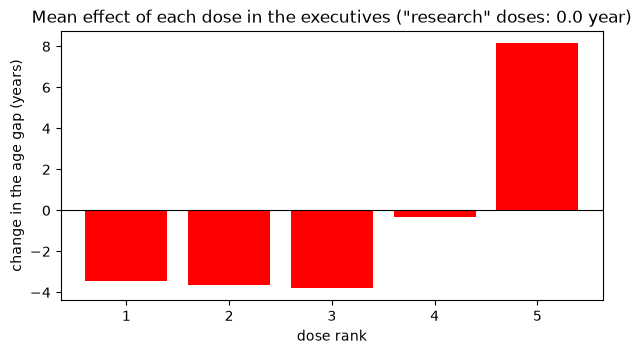

In [11]:
executives_effect = effects[effects["class"] == "restricted_specialist"].groupby("dose rank")["effect (years)"].mean()
research_effect = abs(effects.loc[effects["class"] == "research_restricted", "effect (years)"].mean())
plt.figure(figsize=(7, 3.5))
plt.bar(executives_effect.index, executives_effect.values, color="red")
plt.axhline(0, color="black", linewidth=0.8)
plt.xlabel("dose rank")
plt.ylabel("change in the age gap (years)")
plt.title(f"Mean effect of each dose in the executives (\"research\" doses: {research_effect:.1f} year)")
plt.show()

* Each of the first 3 doses rejuvenates by about 3.5 years: these are the three bars below zero on the chart.
* From the 4th, the effect disappears or reverses. The head of government, the only one to have received a 5th dose, gains 8 years after it in 2024.
* The 20 "research" doses have no effect (0.0 years).

Finally, each injection carries a lot number `MTL-year-number`.

In [12]:
lots, blocks = hu.mrp42_lots(PR, occ)
display(blocks)
display(lots.groupby("series")["number"].agg(["min", "max", "count"]))
display(pd.crosstab(mrp["authorization_class"], mrp["performed_time"].dt.year))

,lots,first_lot,first_injection,occupation_text
patient_number,,,,
PAT-31221,2 to 6,2,2016-02-18,Head of government of Kintara Republic
PAT-31044,7 to 10,7,2017-05-12,Senior minister of the Avelora Federation
PAT-31174,11 to 14,11,2015-09-10,Regional governor in the Tembara Commonwealth
PAT-31119,15 to 18,15,2018-01-26,Chief executive of Solvane Energy Group
PAT-31074,19 to 22,19,2017-11-03,Executive chair of Nivren Maritime Logistics
PAT-31183,23 to 25,23,2016-06-16,Executive director of Ardena Capital Union
PAT-31142,26 to 28,26,2019-03-14,Chair of Belen Agro-Industries
PAT-31099,29 to 31,29,2014-07-18,Retired political intermediary and former coun...


,min,max,count
series,,,
executives (MTL),2,31,30
research (MTL-R),32,51,20


performed_time,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
authorization_class,,,,,,,,,,,,
research_restricted,0,0,0,0,0,1,3,3,2,9,2,0
restricted_specialist,1,1,3,3,4,4,3,3,3,1,3,1


* Lots 2 to 31 are assigned in blocks to each executive, in the order of the hierarchy: head of government, minister, governor, CEOs, then the former intermediary. This is not the chronological order: the intermediary receives lot 29 as early as 2014, two years before lot 2 is used. One may think that the doses were reserved in advance for each executive, but this is a hypothesis.
* Lot no. 1 appears nowhere.
* The "research" series (`MTL-R`, lots 32 to 51) only starts in 2019, five years after the start of the programme. It is not a preliminary trial: it comes afterwards and looks like a cover.

## 3. Nine rejuvenated patients with no declared treatment

Question: were the 9 rejuvenated patients without an `MRP-42` procedure treated in secret?

Methods: care paths (courses 3 and 4), anomalies relative to the patient's history (course 3), clustering of the trajectories by DTW (course 5).

In [13]:
display((pd.crosstab(E["group"], E["encounter_type"], normalize="index") * 100).round(0)
        [["executive_health_review", "specialist_procedure", "cardiac_assessment", "ocular_assessment"]])

breaks = hu.individual_breaks(W2, E, threshold=6)
breaks["group"] = breaks["patient"].map(grp)
display(breaks.sort_values("modified z").round(1))

encounter_type,executive_health_review,specialist_procedure,cardiac_assessment,ocular_assessment
group,,,,
ELITE,56.0,44.0,0.0,0.0
PHENO,0.0,0.0,29.0,22.0
UNDECLARED_REJUVENATED,98.0,0.0,0.0,0.0
other,2.0,0.0,7.0,4.0


,patient,encounter,age gap,patient median,modified z,date,type,group
0,PAT-31011,ENC-000780,-17.8,-7.0,-14.7,2021-05-01,executive_health_review,UNDECLARED_REJUVENATED
5,PAT-31122,ENC-000448,-19.1,-8.8,-13.8,2024-08-03,executive_health_review,UNDECLARED_REJUVENATED
2,PAT-31046,ENC-000347,-18.0,-8.5,-12.8,2025-06-20,executive_health_review,UNDECLARED_REJUVENATED
4,PAT-31110,ENC-000694,-15.9,-6.7,-12.3,2020-05-22,executive_health_review,UNDECLARED_REJUVENATED
1,PAT-31017,ENC-000162,-13.9,-7.3,-8.9,2025-06-20,executive_health_review,UNDECLARED_REJUVENATED
6,PAT-31179,ENC-000264,-13.5,-8.7,-6.4,2022-12-16,executive_health_review,UNDECLARED_REJUVENATED
3,PAT-31071,ENC-000232,-13.6,-9.2,-6.0,2024-02-23,executive_health_review,UNDECLARED_REJUVENATED


* The undeclared rejuvenated patients only have executive reviews (98% of their encounters), like the executives. However, they have no "procedure" encounter, whereas that is where the executives receive their doses. Their only procedures are assessments (age, autonomy, eye tracking…).
* Their path is a simple loop review → review (table of the successions in section 2): it is the executives' cycle without the injection.
* We compare each visit with the same patient's history using a modified z-score. Among the 240 patients, 7 breaks exceed the threshold (z from −6 to −15). They all concern undeclared rejuvenated patients (7 out of 9), always during an executive review, and two fall on 20 June 2025.

Finally, we compare the biological age trajectories with Dynamic Time Warping. DTW realigns series of different lengths and dates. Each trajectory is brought back to 0 at the first visit, then we do a hierarchical clustering on the distances.

In [14]:
from scipy.cluster.hierarchy import linkage, fcluster
from scipy.spatial.distance import squareform

traj = hu.trajectories(W2)
ids, dist = hu.dtw_matrix(traj)
dtw_groups = fcluster(linkage(squareform(dist), "average"), 2, "maxclust")
display(pd.crosstab(pd.Series(dtw_groups, index=ids, name="DTW group"), grp.reindex(ids).rename("group")))

group,ELITE,PHENO,UNDECLARED_REJUVENATED,other
DTW group,,,,
1,0,10,5,212
2,8,0,4,0


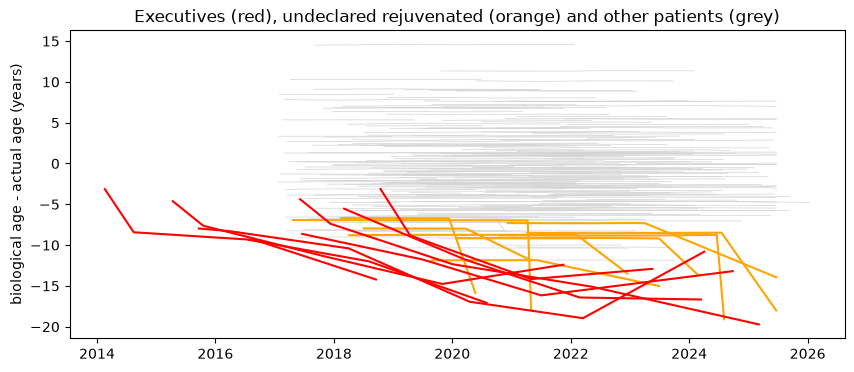

In [15]:
colors = {"ELITE": "red", "UNDECLARED_REJUVENATED": "orange"}
with_age = W2.dropna(subset=["AGE_GAP"])
fig, ax = plt.subplots(figsize=(10, 4))
for group in ["other", "PHENO", "UNDECLARED_REJUVENATED", "ELITE"]:   # the coloured groups are drawn last
    for patient in grp.index[grp == group]:
        d = with_age[with_age["patient_number"] == patient]
        ax.plot(d["encounter_start"], d["AGE_GAP"], color=colors.get(group, "lightgrey"),
                linewidth=1.5 if group in colors else 0.5)
ax.set_ylabel("biological age - actual age (years)")
ax.set_title("Executives (red), undeclared rejuvenated (orange) and other patients (grey)")
plt.show()

On the chart, the executives (in red) gradually go down below the other patients; the undeclared rejuvenated patients (in orange) stay stable then suddenly drop. DTW isolates a pure group of 12 trajectories: the 8 executives and 4 undeclared rejuvenated patients, with no ordinary patient. These patients have the same evolution as the treated executives. They probably received injections that were not recorded.

## 4. 20 June 2025

Method: search for encounters of the same doctor that overlap (contextual anomaly, course 3).

In [16]:
overlap_df = hu.simultaneous_encounters(E)
display(overlap_df.groupby("day").agg(simultaneous=("doctor", "size"), in_two_clinics=("two clinics at once", "sum"))
        .sort_values("simultaneous", ascending=False).head(3))
june20 = E[E["day"] == "2025-06-20"]
second_day = E["day"].value_counts().iloc[1]
planned = (pd.to_datetime(E["follow_up_date"]).dt.date.astype(str) == "2025-06-20").sum()
print("Encounters that day:", len(june20), "| busiest other day:", second_day,
      "| planned in advance as follow-up date:", planned)

,simultaneous,in_two_clinics
day,,
2025-06-20,25,11
2023-06-17,3,2
2018-07-21,1,1


Encounters that day: 22 | busiest other day: 3 | planned in advance as follow-up date: 22


22 encounters take place that day, versus at most 3 on any other day. They were all set months in advance. The doctors are in several encounters at the same time, sometimes in two clinics of two different countries (Valenne and Avelora), which is impossible. These encounters were probably invented, and two undeclared rejuvenated patients "rejuvenate" there. This date is to be looked for in the other datasets.

## 5. Ten patients with unusual physical measurements

Question: do the 10 PHENO patients have a real physical particularity, or are they measurement errors?

Methods: multivariate anomalies (course 3), raw cardiac signal (course 5), mining of the clinical notes (course 6).

In [17]:
from sklearn.ensemble import IsolationForest
from sklearn.neighbors import LocalOutlierFactor

scores = pd.DataFrame({
    "Isolation Forest": -IsolationForest(n_estimators=500, random_state=0).fit(Z).score_samples(Z),
    "LOF": -LocalOutlierFactor(n_neighbors=20).fit(Z).negative_outlier_factor_,
    "ABOD": -np.log(hu.abod(Z)),
}, index=feat.index)
top15 = {}
for method in scores.columns:
    most_abnormal = scores[method].nlargest(15).index
    top15[method] = grp[most_abnormal].value_counts()
print("Group of the 15 most abnormal patients, for each method:")
display(pd.DataFrame(top15).fillna(0).astype(int))

Group of the 15 most abnormal patients, for each method:


,Isolation Forest,LOF,ABOD
PHENO,8,8,9
other,7,7,6


The three methods place 8 or 9 PHENO patients among their 15 most abnormal patients. The notes speak of a "second pulsatile source". We check this on the 44 two-channel ECGs: we detect the beats of each channel, then measure the share of synchronous beats (less than 50 ms apart).

In [18]:
ecg = hu.ecg_synchrony(CR, SIG, height=.9, min_gap_s=.3, tolerance_s=.05)
ecg["group"] = ecg["patient"].map(grp)
display(ecg.groupby("group")["synchronous beats"].agg(["mean", "min", "max", "count"]).round(2))
display((pd.crosstab(E["group"], E["facility_license_number"], normalize="index") * 100).round(0))

,mean,min,max,count
group,,,,
ELITE,1.00,0.98,1.00,4
PHENO,0.18,0.13,0.27,8
UNDECLARED_REJUVENATED,1.00,1.00,1.00,1
other,0.89,0.30,1.00,31


facility_license_number,FAC-AVL-201,FAC-AVL-301,FAC-VLN-101
group,,,
ELITE,47.0,0.0,53.0
PHENO,29.0,31.0,40.0
UNDECLARED_REJUVENATED,33.0,11.0,57.0
other,26.0,10.0,64.0


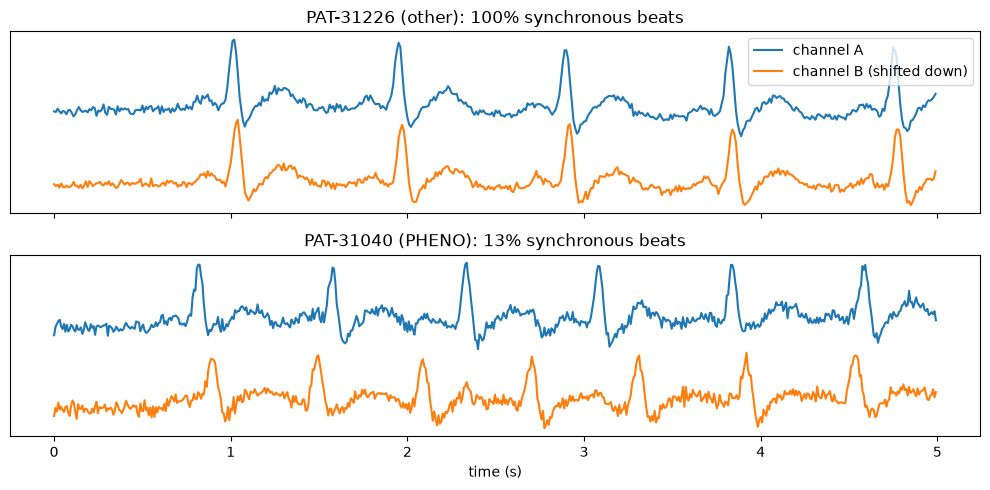

In [19]:
# an ordinary ECG and the least synchronous PHENO ECG, over the first 5 seconds
ordinary = ecg[(ecg["group"] == "other") & (ecg["synchronous beats"] == 1)].iloc[0]
pheno = ecg[ecg["group"] == "PHENO"].sort_values("synchronous beats").iloc[0]
fig, axes = plt.subplots(2, 1, figsize=(10, 5), sharex=True)
for ax, r in zip(axes, [ordinary, pheno]):
    s = SIG[(SIG["recording_id"] == r["recording"]) & (SIG["time_ms"] < 5000)].sort_values("time_ms")
    ax.plot(s["time_ms"] / 1000, s["channel_a_normalized"], label="channel A")
    ax.plot(s["time_ms"] / 1000, s["channel_b_normalized"] - 2.5, label="channel B (shifted down)")
    ax.set_yticks([])
    ax.set_title(f"{r['patient']} ({r['group']}): {r['synchronous beats']:.0%} synchronous beats")
axes[0].legend(loc="upper right")
axes[1].set_xlabel("time (s)")
plt.tight_layout()
plt.show()

On the chart, the peaks of the two channels fall at the same time in the ordinary patient, but drift apart in the PHENO patient.

* In all the other patients, the two channels beat together (almost always 100%). The rare exceptions are faulty devices, which lose beats.
* In the 6 PHENO patients who have an ECG (8 recordings), only 13 to 27% of the beats are synchronous. The two channels each beat at their own rhythm, 16 to 33 beats per minute apart. These are probably two hearts beating separately.
* The PHENO patients often go to the laboratory `FAC-AVL-301` ("Threshold Earth", environmental health research), where the executives never go.

In the clinical notes, we look for those that look like no other. After preparing the text (lowercase, no punctuation, no stop words), each note becomes a TF-IDF vector. We then compute its cosine similarity with the closest note.

In [20]:
import re
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

notes = N.sort_values("document_id").reset_index(drop=True)
notes["group"] = notes["patient_number"].map(grp)
notes["clean_text"] = notes["text"].map(hu.prepare_text)
X_txt = TfidfVectorizer(ngram_range=(1, 2)).fit_transform(notes["clean_text"])
sim = cosine_similarity(X_txt)
np.fill_diagonal(sim, np.nan)
notes["max similarity"] = np.nanmax(sim, axis=1).round(2)
display(notes.sort_values("max similarity")[["document_id", "patient_number", "group", "title", "max similarity"]].head(5))

handwritten = notes.loc[notes["max similarity"] < .3, "document_id"]
with pd.option_context("display.max_colwidth", 160):
    display(hu.unique_sentences(notes, excluded_notes=handwritten)[["patient", "group", "sentence"]])
keys = ["Elias Voss", "public identity", "species", "internal designation", "second, smaller source", "partly independent"]
for c in keys:
    patients = notes.loc[notes["text"].str.contains(c, case=False), "patient_number"].unique()
    print(f"{c} : {', '.join(patients)}")

,document_id,patient_number,group,title,max similarity
3,CLN-510025,PAT-31065,PHENO,Restricted Phenotype and Public-Identity Resol...,0.10
4,CLN-510027,PAT-31065,PHENO,Targeted Thoracic Imaging Review,0.10
12,CLN-510064,PAT-31012,PHENO,Persistent Multisystem Follow-up,0.10
10,CLN-510055,PAT-31115,PHENO,Consultation on Recurrent Capture Discrepancies,0.10
16,CLN-510093,PAT-31222,other,Occupational Health Assessment 22,0.64


,patient,group,sentence
145,PAT-31103,other,Appearance control settings on the camera were restored to default; the prior mismatch resolved after calibration.
414,PAT-31099,ELITE,The phrase dual cardiac structures was entered in the preliminary worksheet but rejected after the apparent second contour disappeared on repeat positioning.


Elias Voss : PAT-31065
public identity : PAT-31065
species : PAT-31065
internal designation : PAT-31065
second, smaller source : PAT-31065
partly independent : PAT-31065, PAT-31012


* 26 notes out of 30 are copied from templates (similarity 0.64 to 0.83). The 4 notes written by hand (similarity 0.10) all concern PHENO patients.
* The note of `PAT-31065` links this patient to a public identity, "Elias Voss", by crossing non-secret attributes (age range, region, clinic history, public role). It specifies that the file establishes "neither a species classification nor an internal designation". These hypotheses were therefore at least considered.
* The only sentences added to the templates are control cases: a camera working again after calibration (`PAT-31103`), and a "dual heart" considered then rejected (`PAT-31099`, whose ECG is indeed synchronous). The PHENO anomalies are therefore not explained by failures.

Finally, we confront the routine notes of the PHENO patients with their measurements.

In [21]:
routine = notes[(notes["group"] == "PHENO") & (notes["max similarity"] > .3)]
table = routine[["document_id", "patient_number"]].join(
    feat[["PULSE_GAP", "N_DISCORDANT", "N_OCULAR_ATYP", "CAMMATCH"]].round(1), on="patient_number")
table["note conclusion"] = routine["text"].str.extract(r"(most consistent with [a-z ]+)")[0]
display(table)

,document_id,patient_number,PULSE_GAP,N_DISCORDANT,N_OCULAR_ATYP,CAMMATCH,note conclusion
0,CLN-510009,PAT-31012,16.2,3.0,3.0,55.0,most consistent with routine variation and the...
1,CLN-510010,PAT-31037,27.0,5.0,4.0,68.0,most consistent with routine variation and the...
19,CLN-510107,PAT-31115,14.5,3.0,2.0,72.2,most consistent with routine variation and the...
21,CLN-510113,PAT-31215,26.3,6.0,0.0,82.6,most consistent with routine variation and the...


These notes conclude on a "routine variation", whereas the measurements show a pulse gap of 15 to 27 bpm and many discordant pulses. The official notes downplay what the data and the restricted notes describe.

## 6. Methods tested without a decisive contribution

These methods were applied (details in appendix 02). They confirm the results above without adding anything, or do not apply to this data.

| Method (course) | Result | Appendix 02 |
|---|---|---|
| Comparison k-means / hierarchical / DBSCAN, t-SNE (2) | same groups; t-SNE separates better than PCA | 2.3, 2.4 |
| Frequent itemsets and association rules, Apriori (3) | restates the two profiles (confidence 100%, lift 5.7 to 15) | 3.1 |
| IQR, z-score, modified z-score (3) | outliers are concentrated in the PHENO, which Isolation Forest already shows | 3.3 |
| Centralities: degree, betweenness, closeness (4) | betweenness about 4 times higher for ELITE and PHENO, hard to interpret | 4.2 |
| Spatial analysis (5) | no regional concentration; Moran and LISA do not apply with 5 regions without neighbourhood | 5.1 |
| Monthly series: trend, seasonality, ACF (5) | no seasonality; June 2025 stands out, which restates 20 June | 5.2 |
| LDA topics (6) | two topics specific to the PHENO, already seen with TF-IDF | 6.4 |

## 7. Bridges to the other datasets

These datasets are studied by the other members of the group. Here, we only read the columns that concern `health`, without cleaning them entirely. Dates are converted with `format="mixed"`; the only ambiguous date of the stock adjustments (`12/11/2023`) concerns another facility, so it changes nothing here.

### 7.1 Injections and stocks (`logistics`)

The clinics have another code in `logistics`, but the same name: `FAC-VLN-101` matches `FCL-1010`, and `FAC-AVL-201` matches `FCL-1007`. For each `MRP-42` injection, we check whether there is a withdrawal of medical consumables the same day, in the same clinic. To know whether this could be chance, we also count the share of days on which such a withdrawal takes place.

In [22]:
adjust = pd.read_csv("../data/logistics/inventory_adjustments.csv", dtype=str)
adjust["date"] = pd.to_datetime(adjust["adjustment_date"], format="mixed").dt.normalize()
withdrawals = adjust[adjust["item_category"] == "medical_consumables"]

clinic = {"FAC-VLN-101": "FCL-1010", "FAC-AVL-201": "FCL-1007"}
mrp["site"] = mrp["performing_facility_license"].map(clinic)
mrp["day"] = mrp["performed_time"].dt.normalize()
withdrawal_days = set(zip(withdrawals["facility_code"], withdrawals["date"]))
mrp["withdrawal the same day"] = [(s, j) in withdrawal_days for s, j in zip(mrp["site"], mrp["day"])]
display(mrp.groupby("authorization_class")["withdrawal the same day"].agg(["sum", "count"]))

period = pd.date_range("2014-07-01", "2025-06-30")
for s in ["FCL-1010", "FCL-1007"]:
    n = withdrawals.loc[withdrawals["facility_code"] == s, "date"].nunique()
    print(f"{s}: a withdrawal of medical consumables on {n} days, i.e. {n / len(period):.1%} of the days")

linked = withdrawals.merge(mrp, left_on=["facility_code", "date"], right_on=["site", "day"])
display(linked["adjustment_reason"].value_counts())

,sum,count
authorization_class,,
research_restricted,0,20
restricted_specialist,30,30


FCL-1010: a withdrawal of medical consumables on 16 days, i.e. 0.4% of the days
FCL-1007: a withdrawal of medical consumables on 14 days, i.e. 0.3% of the days


adjustment_reason
specialist programme issue     11
procedure stock issue          10
controlled-area consumption     9
Name: count, dtype: int64

The 30 injections of the executives all have a stock withdrawal the same day in the same clinic. By chance, this would be very unlikely: these withdrawals only take place on 0.3 to 0.4% of the days. The declared reasons are "specialist programme issue", "procedure stock issue" and "controlled-area consumption". The 20 "research" doses, on the other hand, have no stock withdrawal: they were probably never given, which would explain why they have no effect.

We then look at where the product comes from.

In [23]:
shipments = pd.read_csv("../data/logistics/shipments.csv", dtype=str)
shipments["departure"] = pd.to_datetime(shipments["dispatch_time"], format="mixed")
to_clinics = shipments[shipments["destination_facility_code"].isin(clinic.values())
                        & (shipments["item_category"] == "biological_sample")
                        & shipments["declared_purpose"].str.contains("clinical programme", na=False)]
display(to_clinics.groupby("origin_facility_code").agg(deliveries=("shipment_number", "size"),
                                                           first=("departure", "min"), last=("departure", "max")))
print("first injection:", mrp["performed_time"].min())

,deliveries,first,last
origin_facility_code,,,
FCL-1011,12,2014-07-10 09:00:00,2024-02-22 09:00:00


first injection: 2014-07-18 09:05:00


The clinics receive "biological samples" for a "clinical programme". They all leave from `FCL-1011`, the headquarters of Meridian BioLogistics. The first delivery leaves on 10 July 2014, 8 days before the very first injection.

### 7.2 Public records (`public_records`)

We look for the doctors and patients of `health` in the registers.

In [24]:
professionals = pd.read_csv("../data/public_records/licensed_professionals.csv", dtype=str)
activity = E.groupby("attending_license_number").agg(encounters=("encounter_number", "size"), first=("day", "min"))
display(professionals.set_index("license_number").join(activity, how="inner")[["professional_name", "license_issue_date", "encounters", "first"]])

companies = pd.read_csv("../data/public_records/officer_filings.csv", dtype=str)
display(companies[companies["full_name"].str.contains("Vann|Warden|Vosmere|Voss")]
        [["full_name", "birth_year_or_age_band", "role_title", "appointment_date", "cessation_date"]])

nominations = pd.read_csv("../data/public_records/public_appointments.csv", dtype=str)
access = pd.read_csv("../data/public_records/site_access_case_events.csv", dtype=str)
display(nominations[nominations["office_holder_name"] == "Elira Vaun"][["office_title", "appointment_start", "appointment_end", "departure_reason"]])
display(access[access["authorized_person_name"] == "Elira Vaun"].sort_values("event_time")
        [["access_case_number", "site_code", "event_time", "requesting_organization_name"]])

,professional_name,license_issue_date,encounters,first
license_number,,,,
LIC-VLN-MED-1001,Emil Warden,1895-07-01,147,2015-09-21
LIC-VLN-MED-1002,Dr. Naima Orrel,2002-07-01,162,2014-07-18
LIC-VLN-MED-1003,Dr. Corin Hale,2002-07-01,121,2017-02-05
LIC-VLN-MED-1004,Dr. Lysa Quen,1995-07-01,121,2014-08-15
LIC-VLN-MED-1005,Faris Uren,1986-07-01,119,2015-04-13
LIC-VLN-MED-1006,Farah Havel,2026-07-01,136,2014-02-18
LIC-VLN-RES-1016,Daria Zaven,1990-07-01,140,2017-01-26
LIC-VLN-RES-1044,Ravin Palen,1995-07-01,121,2016-03-22


,full_name,birth_year_or_age_band,role_title,appointment_date,cessation_date
0,Edward Vann,1815,Industrial and shipping adviser,1840-01-01,1888-12-31
1,Emil Warden,1871,Commercial and medical investor,1895-01-01,1943-12-31
2,Adrian Vosmere,1920–1929,Biotechnology and logistics executive,1952-01-01,1991-12-31
3,Dr. Elias Voss,1961,Executive chair of Meridian BioLogistics,1996-01-01,NaN


,office_title,appointment_start,appointment_end,departure_reason
5,Retired political intermediary and former coun...,1965-01-01,2021-09-18,deceased
14,State council secretary,1965-05-01,1979-12-31,role_transition
15,Council president,1980-01-01,1998-12-31,role_transition


,access_case_number,site_code,event_time,requesting_organization_name
211,ACC-2015-0029,KNT-DMJ,2015-11-16T11:00:00,Nordhaven Maritime Safety Agency
175,ACC-2018-0024,KNT-JQG,2018-04-10T09:00:00,Nordhaven Refrigeration Works
180,ACC-2018-0024,KNT-JQG,2018-04-25T11:00:00,Nordhaven Refrigeration Works
369,ACC-2022-0054,AVL-FNM,2022-02-22T09:00:00,Nordhaven Refrigeration Works
341,ACC-2022-0050,AVL-BVM,2022-08-10T09:00:00,Civic Health Purchasing Network
171,ACC-2022-0023,KNT-JAK,2022-10-28T09:00:00,Avelora Orchard Export Union
113,ACC-2024-0015,AVL-MAR,2024-05-10T09:00:00,Horizon Field Research Cooperative
120,ACC-2024-0016,TMB-PEL,2024-07-15T09:00:00,Horizon Field Research Cooperative
226,ACC-2024-0032,KNT-TLQ,2024-08-12T09:00:00,Pelagos Marine Samples Laboratory


* `MED-1001`, one of the most active doctors of the dataset, is registered under the name of Emil Warden, with a license issued in 1895. The company register does contain an Emil Warden born in 1871. He is part of a series of similar names (Edward Vann, Emil Warden, Adrian Vosmere, Elias Voss) whose careers follow one another without overlapping since 1840. The last one, Elias Voss, has chaired Meridian BioLogistics since 1996. One may think of a single person changing identity, like the PHENO patients on camera, but this is a hypothesis.
* `MED-1006` has a license issued in July 2026, although he has been consulting since February 2014.
* Elira Vaun (`PAT-31099`), the former political intermediary of the ELITE group, died on 18 September 2021 according to the appointment register. Yet her name appears as an authorised person in access cases to natural sites in 2022 and 2024. Her identity seems to have been reused.

### 7.3 What the other datasets show

According to the work of the other members of the group (the figures are in their notebooks):
* after each of the 14 observable accesses (out of 18) of the Horizon Field Research Cooperative to bat sites, bat activity drops clearly on the site, and after each of the 18 accesses, a refrigerated shipment leaves 6 h later for a Meridian warehouse;
* in these warehouses, biological lots disappear from the stocks;
* a confidential document (`PUB-510063`, May 2025) speaks of an "unusual clinical population" designated by the word "Chamaeleonidian", and of a "non-terrestrial transfer" to a destination absent from any terrestrial register;
* several PHENO patients have a name close to people in this network, for example Soren Kader and Soren Kade, the author of the Meridian memos. This is only a resemblance.

The `health` dataset shows the end of the chain: the executives' injections, supplied by Meridian. We cannot show that `MRP-42` is made from the bats: the deliveries to the clinics leave from the Meridian headquarters, not from the warehouses where the shipments arrive.

## 8. Conclusion

Independent methods (clustering, anomaly detection, graphs, processes, time series, signal and text) lead to the same two phenomena, on groups of patients that never overlap.

* Rejuvenation programme: 8 executives injected since 2014 by a single doctor, following a regular cycle. The lots are reserved in hierarchical order and lot 1 is missing. A "research" without effect probably serves as a cover. 9 patients are probably treated in secret, and the encounters of 20 June 2025 are most likely invented.
* Probably non-human patients: 10 patients with two hearts, independent eyes and an unstable identity, followed at the Threshold Earth laboratory. Their official notes downplay everything, and one of them is linked to "Elias Voss".

The data dictionary announces in `public_records` a document on "repeated health interventions on executives" and a "biological age divergence". This is exactly our first result.

With the other datasets (section 7), the two phenomena meet: the product injected into the executives arrives through Meridian BioLogistics, chaired by Elias Voss, the name linked to a PHENO patient. Still open: the content of `MRP-42`, lot no. 1, and the license of `MED-1006`.

Names of the ELITE and PHENO patients, for the pooling of results:

In [25]:
cross_keys = P.set_index("patient_number")[["given_name", "family_name", "occupation_text"]].join(grp.rename("group"))
display(cross_keys[cross_keys["group"].isin(["ELITE", "PHENO"])].sort_values("group"))

,given_name,family_name,occupation_text,group
patient_number,,,,
PAT-31099,Elira,Vaun,Retired political intermediary and former coun...,ELITE
PAT-31183,Adrienne,Solva,Executive director of Ardena Capital Union,ELITE
PAT-31074,Oskar,Nivren,Executive chair of Nivren Maritime Logistics,ELITE
PAT-31119,Celene,Varro,Chief executive of Solvane Energy Group,ELITE
PAT-31174,Mirek,Talven,Regional governor in the Tembara Commonwealth,ELITE
PAT-31044,Tavian,Serat,Senior minister of the Avelora Federation,ELITE
PAT-31221,Leora,Kassen,Head of government of Kintara Republic,ELITE
PAT-31142,Rayan,Belen,Chair of Belen Agro-Industries,ELITE
PAT-31037,Sel,Aran,research professional,PHENO


*These are correlations, on synthetic data: several clues point in the same direction, but nothing is proven.*